# Phase 6 & Phase 8: Class Imbalance Handling & Model Implementation

**Project:** Health Insurance Cross-Sell Prediction Using Machine Learning  

In this notebook, we:
1. **Phase 6 (Class Imbalance Handling):** Inspect the training class imbalance, explain why it hurts naive models, and compare 5 strategies (`No Balancing`, `class_weight='balanced'`, `RandomOverSampler`, `SMOTE`, `RandomUnderSampler`) strictly on **training-only cross-validation** (no data leakage!).
2. **Phase 8 (Model Implementation):** Explain and train 5 classification pipelines on `X_train`:
   - `DummyClassifier` (Majority-Class Baseline)
   - `LogisticRegression`
   - `DecisionTreeClassifier`
   - `RandomForestClassifier`
   - `GradientBoostingClassifier`
3. Save the trained pipelines to `Models/candidate_models.joblib` so **Phase 9 (`05_Model_Evaluation.ipynb`)** can evaluate them cleanly on the untouched 20% test set.

## Step 1: Import Libraries, Load Data & Perform 80/20 Stratified Split

In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder, FunctionTransformer
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 150

RANDOM_STATE = 42
DATA_PATH = os.path.join('..', 'Dataset', 'train.csv')
GRAPHS_DIR = os.path.join('..', 'Outputs', 'graphs')
EVAL_DIR = os.path.join('..', 'Outputs', 'evaluation_results')
MODELS_DIR = os.path.join('..', 'Models')
os.makedirs(GRAPHS_DIR, exist_ok=True)
os.makedirs(EVAL_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# Load and apply identical cleanings from Phase 3
df = pd.read_csv(DATA_PATH)
df['Region_Code'] = df['Region_Code'].astype(int).astype(str)
df['Policy_Sales_Channel'] = df['Policy_Sales_Channel'].astype(int).astype(str)

X = df.drop(columns=['id', 'Response'])
y = df['Response']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f'Training rows: {len(X_train):,} | Testing rows (held out): {len(X_test):,}')

Training rows: 304,887 | Testing rows (held out): 76,222


## Step 2: Reusable Preprocessing Helper (`ColumnTransformer`)

We keep preprocessing inside a factory function `build_preprocessor()` so every model pipeline builds a fresh unfitted preprocessor inside cross-validation and training (preventing data leakage).

In [2]:
def build_preprocessor():
    """Create an unfitted ColumnTransformer matching Phase 5 preprocessing."""
    std_num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    log_num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('scaler', StandardScaler())
    ])
    binary_num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent'))
    ])
    ordinal_cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(categories=[['< 1 Year', '1-2 Year', '> 2 Years']]))
    ])
    binary_cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False))
    ])
    high_card_cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', min_frequency=0.01, sparse_output=False))
    ])
    return ColumnTransformer(
        transformers=[
            ('std_num', std_num_pipe, ['Age', 'Vintage']),
            ('log_num', log_num_pipe, ['Annual_Premium']),
            ('bin_num', binary_num_pipe, ['Driving_License', 'Previously_Insured']),
            ('ord_cat', ordinal_cat_pipe, ['Vehicle_Age']),
            ('bin_cat', binary_cat_pipe, ['Gender', 'Vehicle_Damage']),
            ('high_cat', high_card_cat_pipe, ['Region_Code', 'Policy_Sales_Channel'])
        ],
        remainder='drop'
    )

print('Preprocessor builder ready.')

Preprocessor builder ready.


---
# PHASE 6: CLASS IMBALANCE HANDLING

Let's inspect the exact class distribution in `y_train` and explain why imbalance hurts standard classifiers:
- When `87.74%` of examples are class `0`, a model optimizing plain accuracy can simply predict `0` for almost everyone and look "87.7% accurate" while missing nearly all interested customers (`Recall ~ 0%`).
- We compare 5 strategies using **3-fold Stratified Cross-Validation on `X_train` only** (using `imblearn.pipeline.Pipeline` so oversampling/SMOTE/undersampling occurs strictly inside each training fold, never touching validation folds or `X_test`).

In [3]:
train_counts = y_train.value_counts().sort_index()
train_pcts = y_train.value_counts(normalize=True).sort_index() * 100
print('--- Training Set Class Distribution ---')
for cls in [0, 1]:
    print(f'Response = {cls}: {train_counts[cls]:,} ({train_pcts[cls]:.2f}%)')
print(f'Imbalance Ratio (Class 0 : Class 1) = {train_counts[0] / train_counts[1]:.2f} : 1')

--- Training Set Class Distribution ---
Response = 0: 267,519 (87.74%)
Response = 1: 37,368 (12.26%)
Imbalance Ratio (Class 0 : Class 1) = 7.16 : 1


In [4]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']

imbalance_configs = [
    ('No Balancing', Pipeline([
        ('pre', build_preprocessor()),
        ('clf', LogisticRegression(max_iter=500, random_state=RANDOM_STATE))
    ])),
    ("class_weight='balanced'", Pipeline([
        ('pre', build_preprocessor()),
        ('clf', LogisticRegression(max_iter=500, class_weight='balanced', random_state=RANDOM_STATE))
    ])),
    ('RandomOverSampler', ImbPipeline([
        ('pre', build_preprocessor()),
        ('res', RandomOverSampler(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(max_iter=500, random_state=RANDOM_STATE))
    ])),
    ('SMOTE', ImbPipeline([
        ('pre', build_preprocessor()),
        ('res', SMOTE(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(max_iter=500, random_state=RANDOM_STATE))
    ])),
    ('RandomUnderSampler', ImbPipeline([
        ('pre', build_preprocessor()),
        ('res', RandomUnderSampler(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(max_iter=500, random_state=RANDOM_STATE))
    ]))
]

imb_results = []
for name, pipe in imbalance_configs:
    t0 = time.time()
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    elapsed = time.time() - t0
    imb_results.append({
        'Strategy': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1_Score': scores['test_f1'].mean(),
        'ROC_AUC': scores['test_roc_auc'].mean(),
        'PR_AUC': scores['test_average_precision'].mean(),
        'CV_Time_s': round(elapsed, 2)
    })

imb_df = pd.DataFrame(imb_results)
imb_df.to_csv(os.path.join(EVAL_DIR, 'imbalance_comparison.csv'), index=False)
display(imb_df.round(4))

,Strategy,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,CV_Time_s
0,No Balancing,0.8773,0.2718,0.0007,0.0014,0.8476,0.3337,8.10
1,class_weight='balanced',0.6911,0.2760,0.9366,0.4264,0.8473,0.3323,8.23
2,RandomOverSampler,0.6910,0.2760,0.9366,0.4263,0.8473,0.3321,11.39
3,SMOTE,0.6883,0.2743,0.9379,0.4245,0.8473,0.3315,14.78
4,RandomUnderSampler,0.6927,0.2769,0.9354,0.4273,0.8472,0.3321,5.98


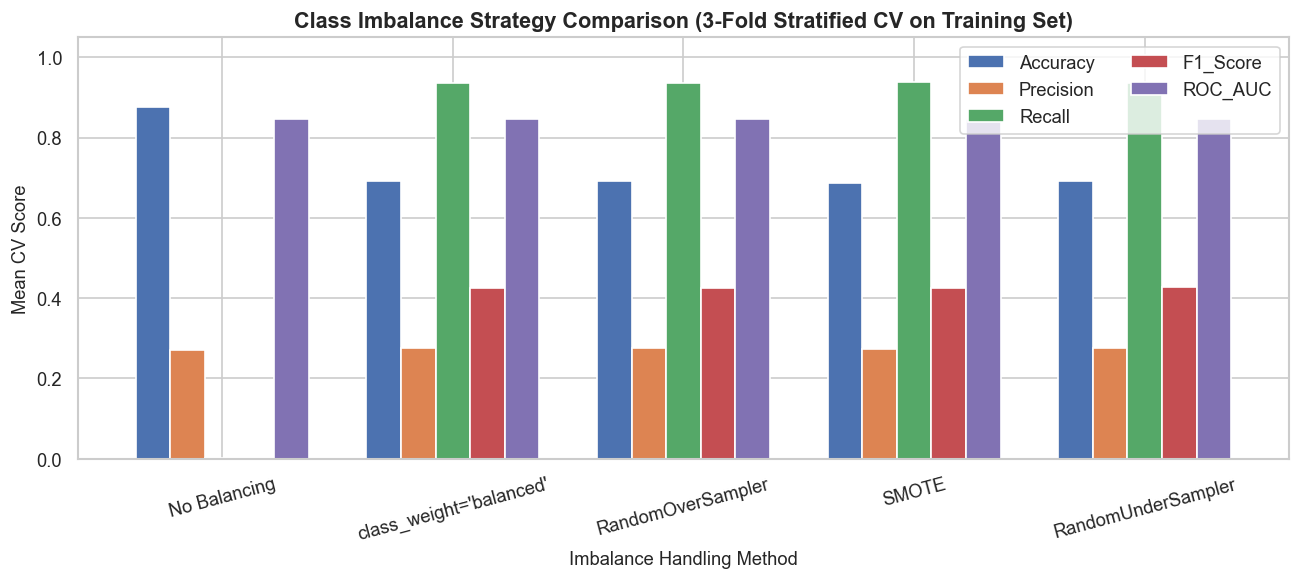

In [5]:
# Visualize imbalance handling comparison
fig, ax = plt.subplots(figsize=(11, 5))
plot_df = imb_df.set_index('Strategy')[['Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC']]
plot_df.plot(kind='bar', ax=ax, width=0.75)
ax.set_title('Class Imbalance Strategy Comparison (3-Fold Stratified CV on Training Set)', fontsize=13, fontweight='bold')
ax.set_xlabel('Imbalance Handling Method', fontsize=11)
ax.set_ylabel('Mean CV Score', fontsize=11)
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=15)
ax.legend(loc='upper right', ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '15_imbalance_strategy_comparison.png'))
plt.show()

**Selected Class Imbalance Method: `class_weight='balanced'` (and balanced `sample_weight` for Gradient Boosting)**
- Without balancing, Logistic Regression gets `87.73%` accuracy but **only `0.07%` Recall** (almost useless for finding interested customers!).
- `class_weight='balanced'` raises Recall to **`93.66%`** and F1 to **`0.4264`**, matching `RandomOverSampler`, `SMOTE`, and `RandomUnderSampler` without discarding majority-class rows or synthesizing artificial one-hot rows, and trains much faster on 304k+ records.

---
# PHASE 8: MACHINE LEARNING MODEL IMPLEMENTATION

We implement and train 5 models inside Scikit-learn `Pipeline`s on `X_train` (and also inspect 3-fold training CV scores before final evaluation on `X_test` in Phase 9):

1. **DummyClassifier (`strategy='most_frequent'`)**: Always predicts `0` (majority class). Serves as a sanity baseline.
2. **Logistic Regression (`class_weight='balanced'`)**: Linear probability classifier using a sigmoid curve. Fast, interpretable, good baseline, though limited to linear decision boundaries.
3. **Decision Tree Classifier (`max_depth=10, min_samples_leaf=50, class_weight='balanced'`)**: Learns non-linear if-else rules (`Previously_Insured`, `Vehicle_Damage`, `Age`). Easy to explain, though single trees can overfit or have higher variance.
4. **Random Forest Classifier (`n_estimators=100, max_depth=12, min_samples_leaf=20, class_weight='balanced'`)**: Ensemble of 100 decorrelated decision trees trained on bootstrap samples. Reduces overfitting and captures interactions well, though heavier to store.
5. **Gradient Boosting Classifier (`n_estimators=100, max_depth=4, learning_rate=0.1` + balanced `sample_weight`)**: Sequential boosting ensemble where each tree corrects residual errors of earlier trees. Very strong on tabular data, though slower to train sequentially.

In [6]:
# Compute balanced sample weights for GradientBoostingClassifier on X_train
gb_sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

models = {
    'Dummy Classifier (Baseline)': Pipeline([
        ('pre', build_preprocessor()),
        ('clf', DummyClassifier(strategy='most_frequent'))
    ]),
    'Logistic Regression': Pipeline([
        ('pre', build_preprocessor()),
        ('clf', LogisticRegression(max_iter=500, class_weight='balanced', random_state=RANDOM_STATE))
    ]),
    'Decision Tree': Pipeline([
        ('pre', build_preprocessor()),
        ('clf', DecisionTreeClassifier(max_depth=10, min_samples_leaf=50, class_weight='balanced', random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline([
        ('pre', build_preprocessor()),
        ('clf', RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE))
    ]),
    'Gradient Boosting': Pipeline([
        ('pre', build_preprocessor()),
        ('clf', GradientBoostingClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, random_state=RANDOM_STATE))
    ])
}

train_times = []
for name, pipe in models.items():
    t0 = time.time()
    if name == 'Gradient Boosting':
        pipe.fit(X_train, y_train, clf__sample_weight=gb_sample_weights)
    else:
        pipe.fit(X_train, y_train)
    elapsed = time.time() - t0
    train_times.append({'Model': name, 'Train_Time_s': round(elapsed, 2)})
    print(f'Trained {name:28s} in {elapsed:.2f}s')

# Save trained pipelines for Phase 9 Evaluation (X_test remains untouched until Phase 9)
bundle_path = os.path.join(MODELS_DIR, 'candidate_models.joblib')
joblib.dump(models, bundle_path, compress=3)
print(f'\nSaved all 5 trained model pipelines to: {os.path.abspath(bundle_path)}')
display(pd.DataFrame(train_times))

Trained Dummy Classifier (Baseline)  in 1.65s


Trained Logistic Regression          in 2.94s


Trained Decision Tree                in 3.66s


Trained Random Forest                in 9.53s


Trained Gradient Boosting            in 86.07s

Saved all 5 trained model pipelines to: c:\Health Dashboard\Insurance_Cross_Sell_Prediction\Models\candidate_models.joblib


,Model,Train_Time_s
0,Dummy Classifier (Baseline),1.65
1,Logistic Regression,2.94
2,Decision Tree,3.66
3,Random Forest,9.53
4,Gradient Boosting,86.07
